In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
data = pd.read_csv('2024_25_mlb_pitches.csv')

(array([81850., 35506., 32684., 22046., 20035., 18547., 15859.,  9850.,
        10541., 14142.]),
 array([0.001 , 0.1008, 0.2006, 0.3004, 0.4002, 0.5   , 0.5998, 0.6996,
        0.7994, 0.8992, 0.999 ]),
 <BarContainer object of 10 artists>)

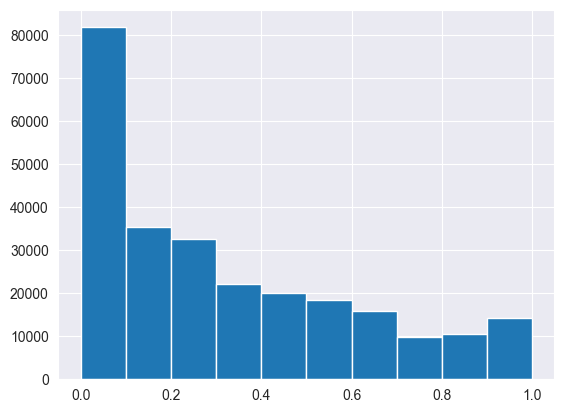

In [23]:
plt.hist(data['estimated_ba_using_speedangle'][data['estimated_ba_using_speedangle'].notna()])

(array([150504.,  49234.,  36959.,   7111.,   4296.,   4332.,   2640.,
          2132.,   1957.,   1895.]),
 array([1.0000e-03, 4.0070e-01, 8.0040e-01, 1.2001e+00, 1.5998e+00,
        1.9995e+00, 2.3992e+00, 2.7989e+00, 3.1986e+00, 3.5983e+00,
        3.9980e+00]),
 <BarContainer object of 10 artists>)

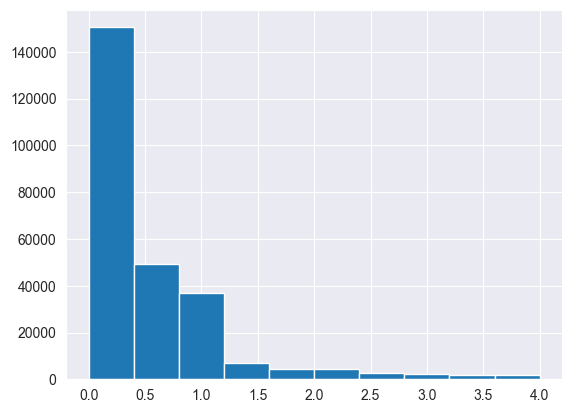

In [24]:
plt.hist(data['estimated_slg_using_speedangle'][data['estimated_slg_using_speedangle'].notna()])

In [26]:
data[['estimated_ba_using_speedangle', 'estimated_slg_using_speedangle']][data['estimated_ba_using_speedangle'].notna()].describe()

,estimated_ba_using_speedangle,estimated_slg_using_speedangle
count,261060.000000,261060.000000
mean,0.319146,0.540150
std,0.284968,0.672132
min,0.001000,0.001000
25%,0.066000,0.088000
50%,0.239000,0.296000
75%,0.519000,0.753000
max,0.999000,3.998000


In [3]:
data.columns

Index(['Unnamed: 0', 'pitch_type', 'game_date', 'release_speed',
       'release_pos_x', 'release_pos_z', 'player_name', 'batter', 'pitcher',
       'events',
       ...
       'batter_days_until_next_game', 'api_break_z_with_gravity',
       'api_break_x_arm', 'api_break_x_batter_in', 'arm_angle', 'attack_angle',
       'attack_direction', 'swing_path_tilt',
       'intercept_ball_minus_batter_pos_x_inches',
       'intercept_ball_minus_batter_pos_y_inches'],
      dtype='object', length=119)

In [9]:
def add_swing_whiff_flags(df):
    """
    Add is_whiff and is_swing columns based on MLB 'description' field.
    """
    df = df.copy()

    # Whiffs: only swinging strikes
    df["is_whiff"] = df["description"] == "swinging_strike"

    # Swings: whiffs + fouls + balls put in play
    swing_events = [
        "swinging_strike",
        "foul",
        "hit_into_play"
    ]

    df["is_swing"] = df["description"].isin(swing_events)

    return df


In [10]:
data_events = add_swing_whiff_flags(data)

In [11]:
data_skinny = data_events[['batter', 'game_date', 'launch_speed', 'is_whiff', 'is_swing']].copy()


In [12]:
data_skinny["season"] = pd.to_datetime(data_skinny["game_date"]).dt.year

In [13]:
def sample_ev95(group, n):
    sample = group.sample(n, replace=False)
    return np.percentile(sample["launch_speed"], 95)


In [14]:
def sample_aggregate(group, n, column, agg_fn):
    """
    Sample n rows from the group and compute an aggregate on the chosen column.

    Parameters
    ----------
    group : DataFrame
        Player-season subset.
    n : int
        Sample size.
    column : str
        Column to aggregate.
    agg_fn : callable
        Function applied to the sampled column values.

    Returns
    -------
    float
        Aggregated metric value.
    """
    sample = group.sample(n, replace=False)
    return agg_fn(sample[column])


In [15]:
METRIC_REGISTRY = {
    "ev95": sample_ev95,

    "mean_ev": lambda g, n: sample_aggregate(g, n, "launch_speed", np.mean),

    "barrel_rate": lambda g, n: sample_aggregate(g, n, "is_barrel", np.mean) / n,

    "whiff_rate": lambda g, n: sample_aggregate(g, n, "is_whiff", np.mean) / n,

    "swing_rate": lambda g, n: sample_aggregate(g, n, "is_swing", np.mean) / n,

}



    # add more as needed:
    # "whiff_rate": ...
    # "pull_air_pct": ...


In [16]:
def reliability_for_n(data_skinny, n, metric_name, iterations=200):
    """
    Compute reliability(n) for a named metric in METRIC_REGISTRY.

    Parameters
    ----------
    data_skinny : DataFrame
        Must contain ["batter", "season"] and the fields required by the metric.
    n : int
        Sample size per player-season.
    metric_name : str
        Name of the metric in METRIC_REGISTRY.
    iterations : int
        Number of bootstrap iterations.

    Returns
    -------
    float
        Reliability estimate: between-player-season variance / total variance.
    """
    if metric_name not in METRIC_REGISTRY:
        raise ValueError(f"Unknown metric: {metric_name}")

    metric_fn = METRIC_REGISTRY[metric_name]
    results = []

    # group by player-season
    grouped = data_skinny.groupby(["batter", "season"])

    # only keep player-seasons with at least n BBE
    eligible = {k: g for k, g in grouped if len(g) >= n}

    if len(eligible) < 5:
        return np.nan  # too few player-seasons

    # bootstrap sampling
    for _ in range(iterations):
        metric_values = []
        for (batter, season), g in eligible.items():
            metric_values.append(metric_fn(g, n))
        results.append(metric_values)

    # convert to matrix: iterations × player-seasons
    M = np.array(results)

    # reliability = between-player-season variance / total variance
    total_var = M.var()
    between_var = M.mean(axis=0).var()

    return between_var / total_var



In [17]:
data_swings = data_skinny[data_skinny['is_swing'] == True].copy()

In [18]:
def find_min_sample_size_for_reliability(data_skinny, sample_sizes, metric_name,
                                         threshold=0.7, iterations=200):
    """
    Evaluate reliability across sample sizes and return the smallest n
    where reliability >= threshold.

    Parameters
    ----------
    data_skinny : DataFrame
        Player-season dataset.
    sample_sizes : list[int]
        List of sample sizes to evaluate.
    metric_name : str
        Name of the metric in METRIC_REGISTRY.
    threshold : float
        Reliability threshold (default 0.7).
    iterations : int
        Bootstrap iterations for reliability_for_n.

    Returns
    -------
    int or None
        The smallest n where reliability >= threshold, or None if not reached.
    """
    results = {}

    for n in sample_sizes:
        r = reliability_for_n(data_skinny, n, metric_name, iterations=iterations)
        results[n] = r
        print(f"n={n}: reliability={r}")

        if r is not None and not np.isnan(r) and r >= threshold:
            return n  # earliest stabilization point

    return None  # threshold never reached



In [22]:
sample_sizes = list(range(30, 301, 30))

min_n = find_min_sample_size_for_reliability(
    data_skinny,
    sample_sizes,
    metric_name="swing_rate",
    threshold=0.7
)

print("Minimum n for reliability ≥ 0.7:", min_n)


KeyboardInterrupt: 

In [ ]:
plt.plot(sample_sizes, reliabilities, marker='o')
plt.xlabel("Sample size (BBE)")
plt.ylabel("Reliability of ev95")
plt.title("ev95 Reliability Curve (Player-Season Sampling)")
plt.grid(True)
plt.show()
